In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from scipy.stats import linregress


In [2]:
# ==========================================================
# Read NetCDF Files
# ==========================================================

OCCI_FILE = r"../merged_glory_chla_colocated_100.nc"
LGBM_FILE = r"LGBM_East_Arabian_Sea_predictions_1998_2025.nc"

ds_occci = xr.open_dataset(OCCI_FILE)

ds_lgbm = xr.open_dataset(LGBM_FILE)



ds_gapfree = xr.open_dataset("chl_gapfree_monthly_1998_2025_EAS_BOB.nc")

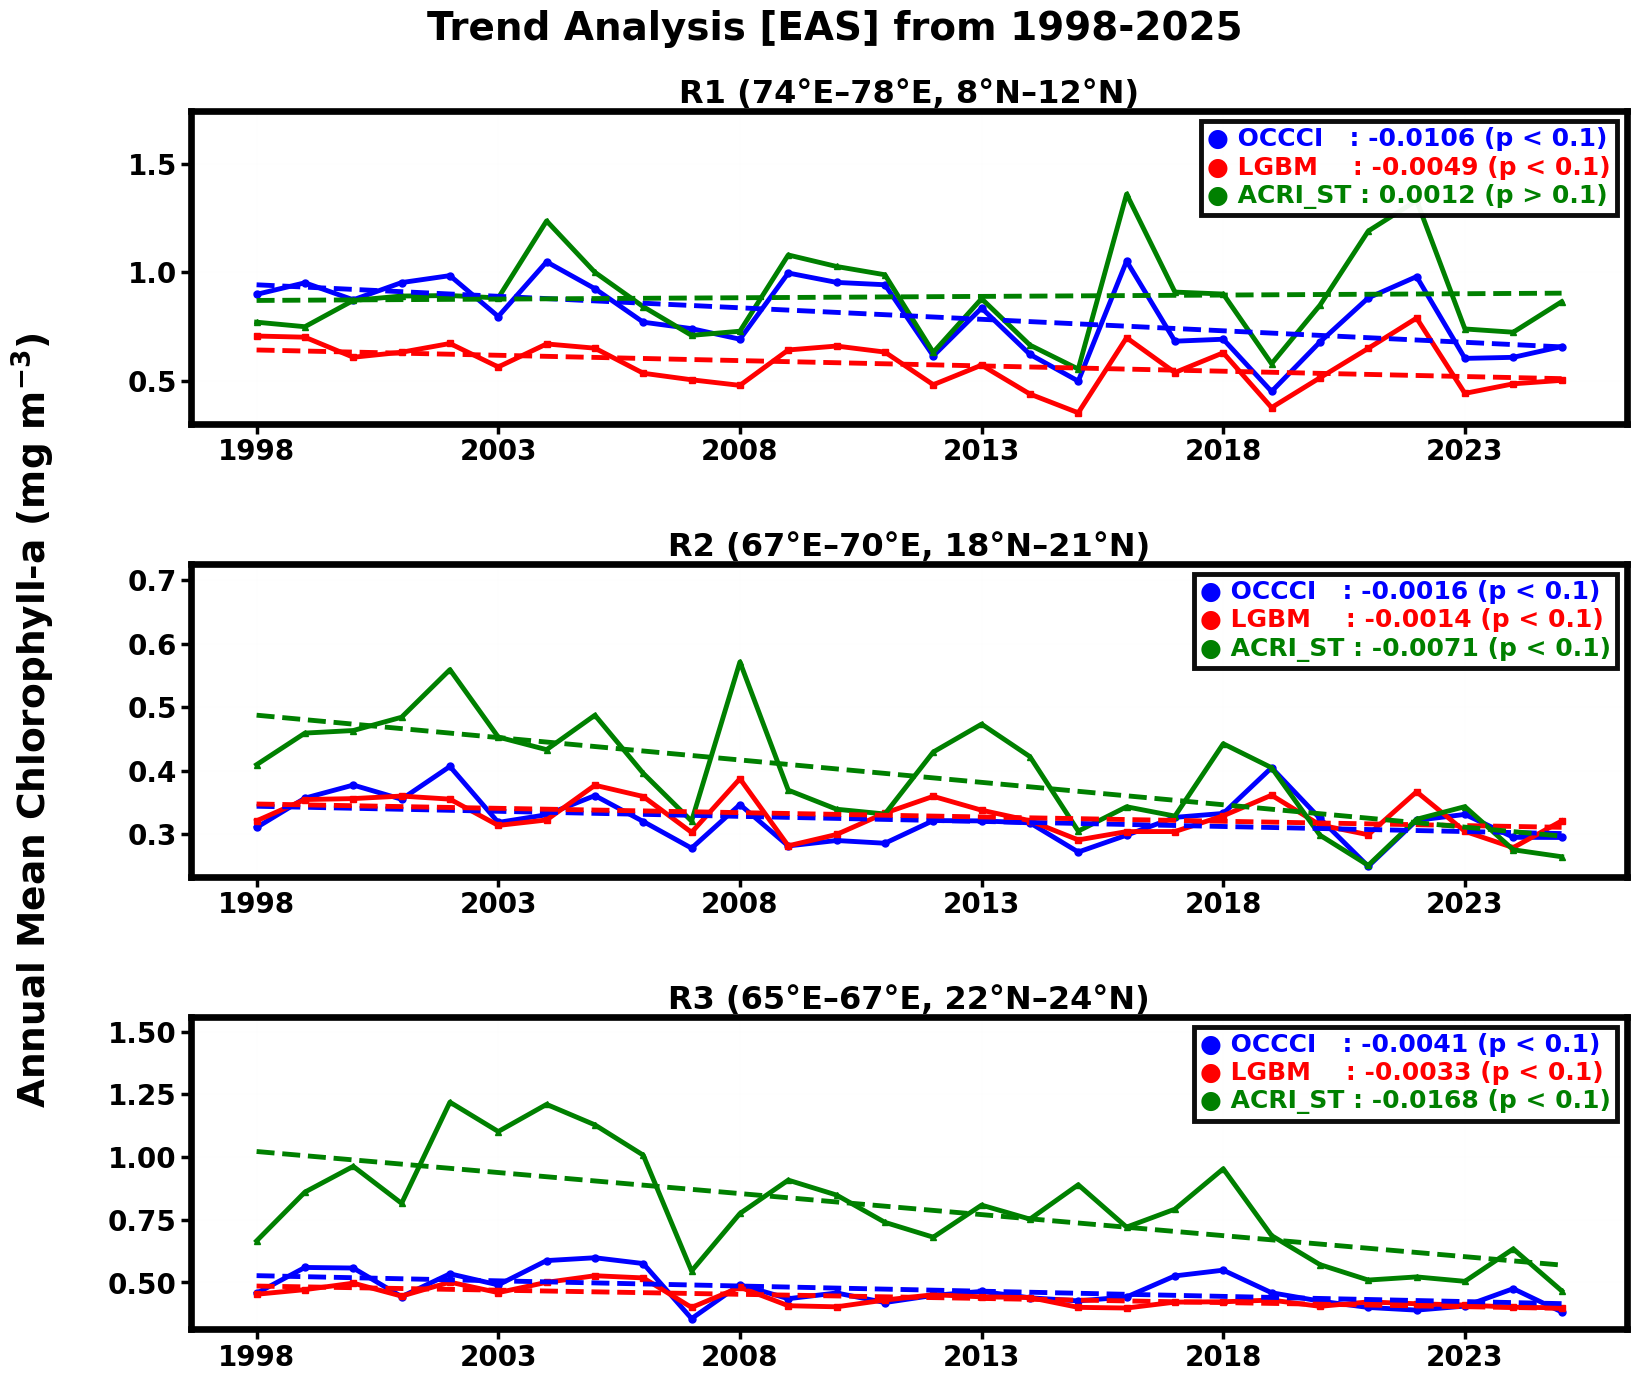

In [27]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# BOB Subregions (1998–2025)
# ==========================================================

from matplotlib.offsetbox import TextArea, VPacker, AnchoredOffsetbox




# ==========================================================
# Subregions (EAS)
# ==========================================================

regions = {
    "R1 (74°E–78°E, 8°N–12°N)"  : [74.0, 78.0, 8.0, 12.0],
    "R2 (67°E–70°E, 18°N–21°N)" : [67.0, 70.0, 18.0, 21.0],
    "R3 (65°E–67°E, 22°N–24°N)" : [65.0, 67.0, 22.0, 24.0],
}

# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"



# ==========================================================
# Figure
# ==========================================================

fig = plt.figure(figsize=(16.5, 14.5))

gs = fig.add_gridspec(
    nrows=3,
    ncols=1,
    height_ratios=[1.25]*3,
    hspace=0.45
)

plot_axes = []

for i in range(3):
    plot_axes.append(
        fig.add_subplot(gs[i])
    )




# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"
    
    
      
    
# ==========================================================
# Loop over regions
# ==========================================================

stats_list = []
for ax, (region_name, box) in zip(plot_axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # Annual Mean
    # ------------------------------------------------------

    # Annual means
    obs_year = obs.groupby("time.year").mean()
    pred_year = pred.groupby("time.year").mean()
    gap_year = gap.groupby("time.year").mean()

    # Convert to pandas Series
    obs_series = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series = gap_year.to_series()

    # Keep only common years
    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    obs_p_txt  = format_p(obs_fit.pvalue)
    pred_p_txt = format_p(pred_fit.pvalue)
    gap_p_txt  = format_p(gap_fit.pvalue)
    
    

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=3.5,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=3.5,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=3.5,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=3.5,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=3.5,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=3.5,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=23,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.02,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(1998,2026,5)
    )

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=20,
        width=2.5,
        length=7
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(4.8)
        
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.23450)    
    
    # ------------------------------------------------------
    # Statistics Box
    # ------------------------------------------------------

    obs_box = TextArea(
        f"● OCCCI   : {obs_fit.slope:.4f} ({obs_p_txt})",
        textprops=dict(
            color="blue",
            fontsize=18,
            fontweight="bold"
        )
    )

    pred_box = TextArea(
        f"● LGBM    : {pred_fit.slope:.4f} ({pred_p_txt})",
        textprops=dict(
            color="red",
            fontsize=18,
            fontweight="bold"
        )
    )

    gap_box = TextArea(
        f"● ACRI_ST : {gap_fit.slope:.4f} ({gap_p_txt})",
        textprops=dict(
            color="green",
            fontsize=18,
            fontweight="bold"
        )
    )

    stats_box = VPacker(
        children=[obs_box, pred_box, gap_box],
        align="left",
        pad=0,
        sep=3
    )

    anchored_box = AnchoredOffsetbox(
        loc="upper right",
        child=stats_box,
        frameon=True,
        borderpad=0.7,
        pad=0.45
    )

    anchored_box.patch.set_facecolor("white")
    anchored_box.patch.set_edgecolor("black")
    anchored_box.patch.set_linewidth(3.5)
    anchored_box.patch.set_alpha(0.95)

    ax.add_artist(anchored_box)
    
    

    
    
    
# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.0001,
    0.5,
    "Annual Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=27,
    fontweight="bold"
)




# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Trend Analysis [EAS] from 1998-2025",
    fontsize=28,
    fontweight="bold",
    x= 0.50,
    y=0.99
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.92,
    bottom=0.08,
    left=0.11,
    right=0.98,
    hspace=0.45
)






plt.show()




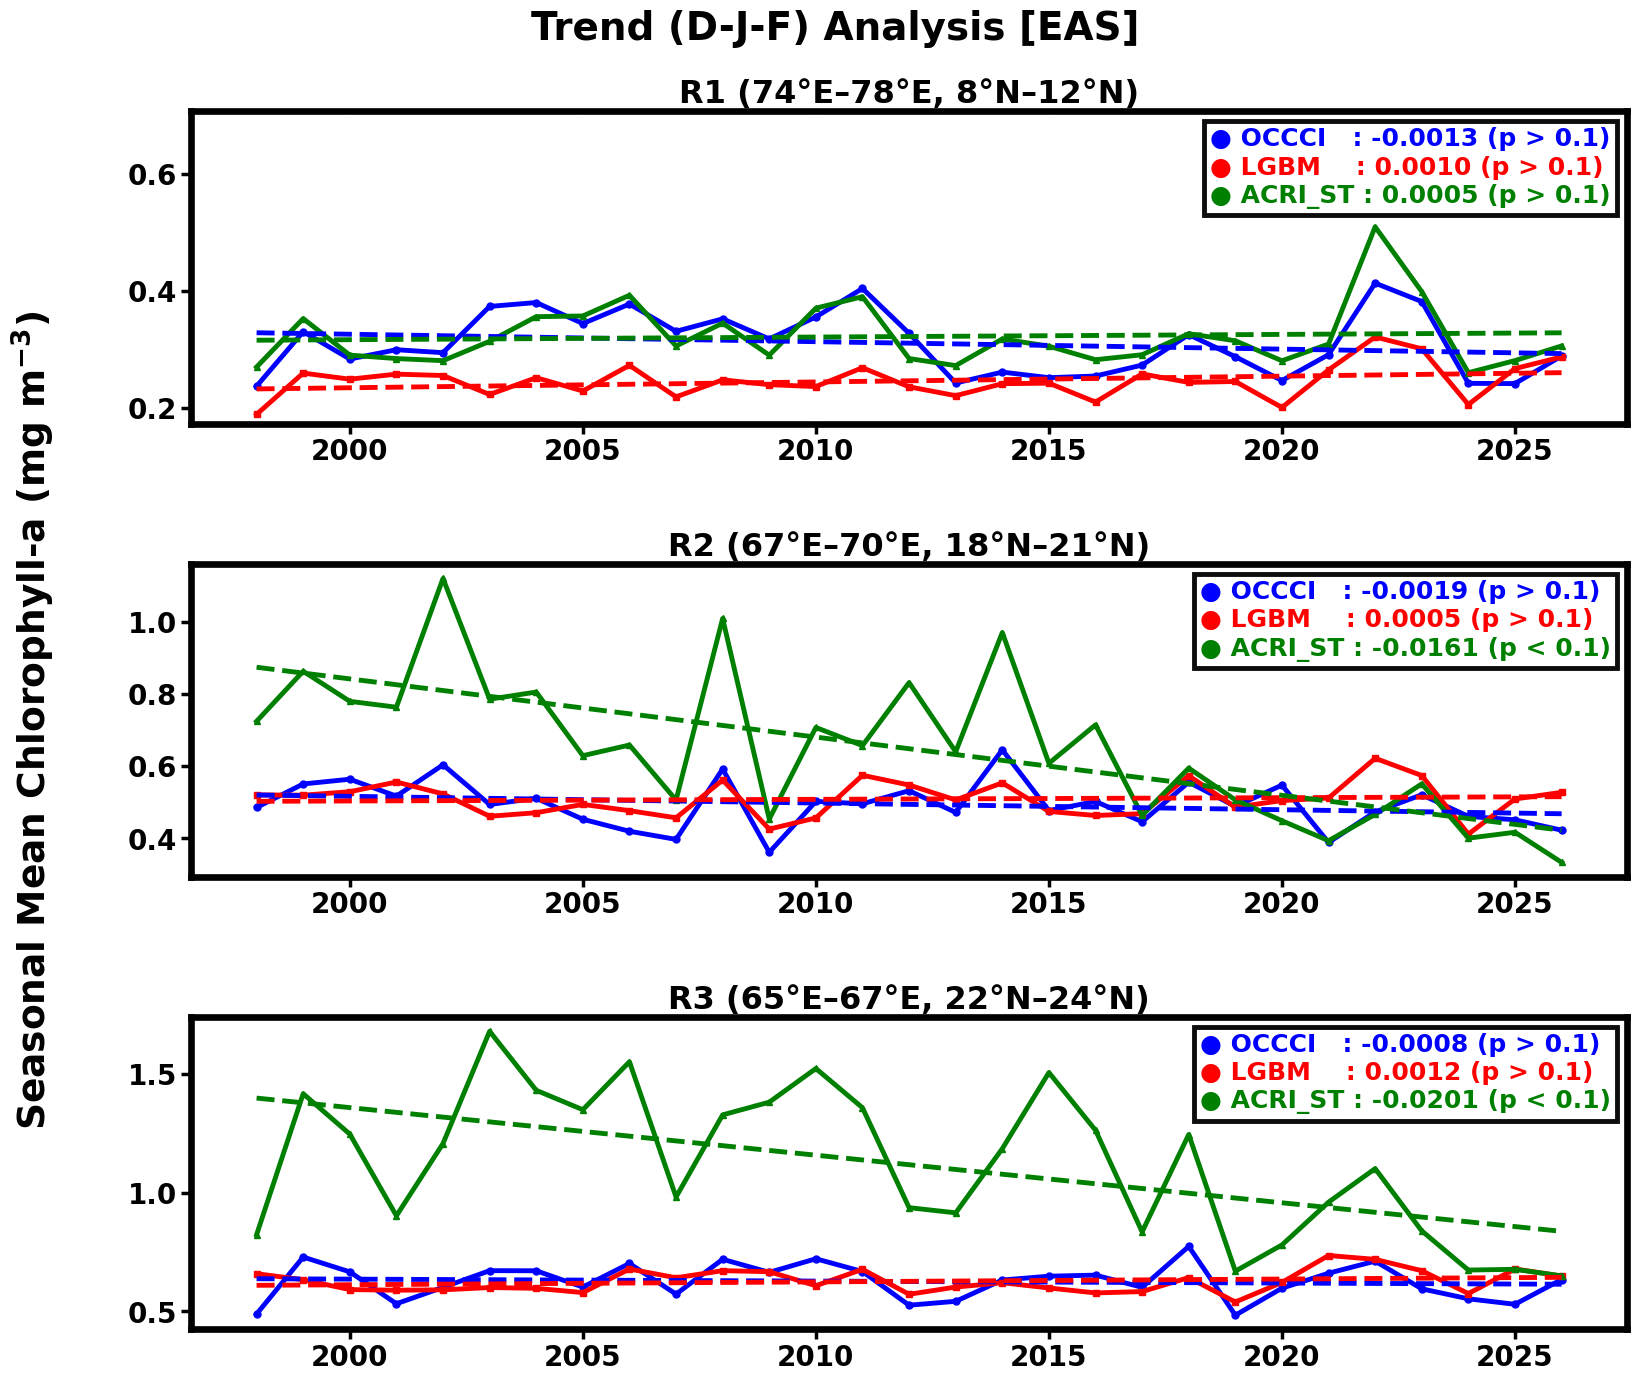

In [31]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# BOB Subregions (1998–2025)
# ==========================================================

from matplotlib.offsetbox import TextArea, VPacker, AnchoredOffsetbox




# ==========================================================
# Subregions (EAS)
# ==========================================================

regions = {
    "R1 (74°E–78°E, 8°N–12°N)"  : [74.0, 78.0, 8.0, 12.0],
    "R2 (67°E–70°E, 18°N–21°N)" : [67.0, 70.0, 18.0, 21.0],
    "R3 (65°E–67°E, 22°N–24°N)" : [65.0, 67.0, 22.0, 24.0],
}

# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"



# ==========================================================
# Figure
# ==========================================================

fig = plt.figure(figsize=(16.5, 14.5))

gs = fig.add_gridspec(
    nrows=3,
    ncols=1,
    height_ratios=[1.25]*3,
    hspace=0.45
)

plot_axes = []

for i in range(3):
    plot_axes.append(
        fig.add_subplot(gs[i])
    )




# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"
    
    
      
    
# ==========================================================
# Loop over regions
# ==========================================================

stats_list = []
for ax, (region_name, box) in zip(plot_axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # DJF Seasonal Mean
    # ------------------------------------------------------

    def seasonal_mean_DJF(da):

        # Keep only December, January and February
        da = da.where(da.time.dt.season == "DJF", drop=True)

        # Assign December to the following year's season
        season_year = xr.where(
            da.time.dt.month == 12,
            da.time.dt.year + 1,
            da.time.dt.year
        )

        da = da.assign_coords(
            season_year=("time", season_year.data)
        )

        # Average each DJF season
        return da.groupby("season_year").mean()

    obs_year  = seasonal_mean_DJF(obs)
    pred_year = seasonal_mean_DJF(pred)
    gap_year  = seasonal_mean_DJF(gap)

    # Convert to pandas Series
    obs_series = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series = gap_year.to_series()

    # Keep only common years
    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    obs_p_txt  = format_p(obs_fit.pvalue)
    pred_p_txt = format_p(pred_fit.pvalue)
    gap_p_txt  = format_p(gap_fit.pvalue)
    
    

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=3.5,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=3.5,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=3.5,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=3.5,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=3.5,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=3.5,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=23,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.02,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(2000,2026,5)
    )

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=20,
        width=2.5,
        length=7
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(4.8)
        
    # ------------------------------------------------------
    # Increase y-axis only for selected subplot(s)
    # ------------------------------------------------------

    if region_name == "R1 (74°E–78°E, 8°N–12°N)":
        ymin, ymax = ax.get_ylim()
        ax.set_ylim(ymin, ymax * 1.3450)    
    
    # ------------------------------------------------------
    # Statistics Box
    # ------------------------------------------------------

    obs_box = TextArea(
        f"● OCCCI   : {obs_fit.slope:.4f} ({obs_p_txt})",
        textprops=dict(
            color="blue",
            fontsize=18,
            fontweight="bold"
        )
    )

    pred_box = TextArea(
        f"● LGBM    : {pred_fit.slope:.4f} ({pred_p_txt})",
        textprops=dict(
            color="red",
            fontsize=18,
            fontweight="bold"
        )
    )

    gap_box = TextArea(
        f"● ACRI_ST : {gap_fit.slope:.4f} ({gap_p_txt})",
        textprops=dict(
            color="green",
            fontsize=18,
            fontweight="bold"
        )
    )

    stats_box = VPacker(
        children=[obs_box, pred_box, gap_box],
        align="left",
        pad=0,
        sep=3
    )

    anchored_box = AnchoredOffsetbox(
        loc="upper right",
        child=stats_box,
        frameon=True,
        borderpad=0.7,
        pad=0.45
    )

    anchored_box.patch.set_facecolor("white")
    anchored_box.patch.set_edgecolor("black")
    anchored_box.patch.set_linewidth(3.5)
    anchored_box.patch.set_alpha(0.95)

    ax.add_artist(anchored_box)
    
    

    
    
    
# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.0001,
    0.5,
    "Seasonal Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=27,
    fontweight="bold"
)




# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Trend (D-J-F) Analysis [EAS]",
    fontsize=28,
    fontweight="bold",
    x= 0.50,
    y=0.99
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.92,
    bottom=0.08,
    left=0.11,
    right=0.98,
    hspace=0.45
)






plt.show()




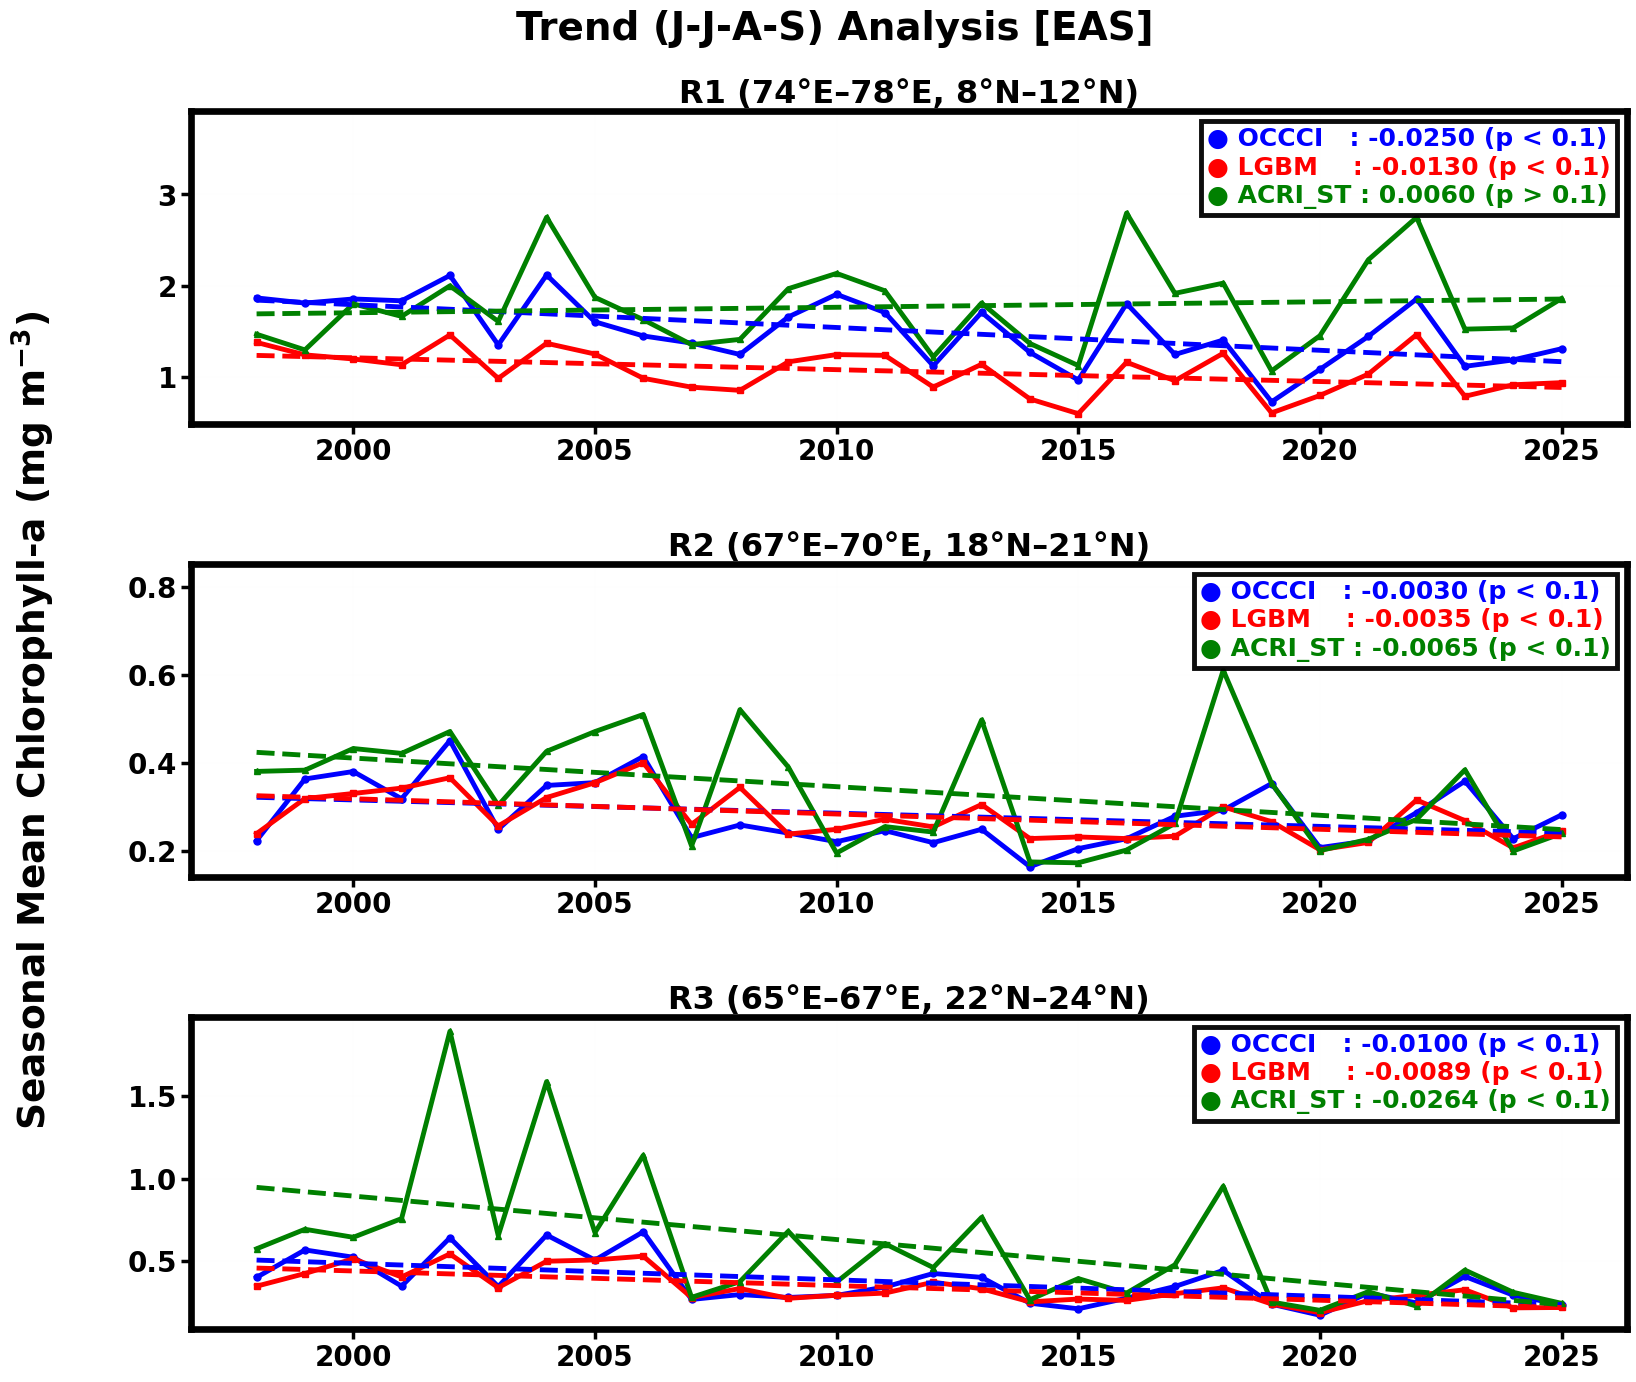

In [34]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# BOB Subregions (1998–2025)
# ==========================================================

from matplotlib.offsetbox import TextArea, VPacker, AnchoredOffsetbox




# ==========================================================
# Subregions (EAS)
# ==========================================================

regions = {
    "R1 (74°E–78°E, 8°N–12°N)"  : [74.0, 78.0, 8.0, 12.0],
    "R2 (67°E–70°E, 18°N–21°N)" : [67.0, 70.0, 18.0, 21.0],
    "R3 (65°E–67°E, 22°N–24°N)" : [65.0, 67.0, 22.0, 24.0],
}

# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"



# ==========================================================
# Figure
# ==========================================================

fig = plt.figure(figsize=(16.5, 14.5))

gs = fig.add_gridspec(
    nrows=3,
    ncols=1,
    height_ratios=[1.25]*3,
    hspace=0.45
)

plot_axes = []

for i in range(3):
    plot_axes.append(
        fig.add_subplot(gs[i])
    )




# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"
    
    
      
    
# ==========================================================
# Loop over regions
# ==========================================================

stats_list = []
for ax, (region_name, box) in zip(plot_axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # JJAS Seasonal Mean
    # ------------------------------------------------------

    def seasonal_mean_JJAS(da):

        # Keep only June, July, August and September
        da = da.where(da.time.dt.month.isin([6, 7, 8, 9]), drop=True)

        # Average JJAS for each calendar year
        return da.groupby("time.year").mean()

    obs_year  = seasonal_mean_JJAS(obs)
    pred_year = seasonal_mean_JJAS(pred)
    gap_year  = seasonal_mean_JJAS(gap)

    # Convert to pandas Series
    obs_series = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series = gap_year.to_series()

    # Keep only common years
    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    obs_p_txt  = format_p(obs_fit.pvalue)
    pred_p_txt = format_p(pred_fit.pvalue)
    gap_p_txt  = format_p(gap_fit.pvalue)
    
    

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=3.5,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=3.5,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=3.5,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=3.5,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=3.5,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=3.5,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=23,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.02,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(2000,2026,5)
    )

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=20,
        width=2.5,
        length=7
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(4.8)
        
    # ------------------------------------------------------
    # Increase y-axis only for selected subplot(s)
    # ------------------------------------------------------

    if region_name in [
        "R1 (74°E–78°E, 8°N–12°N)",
        "R2 (67°E–70°E, 18°N–21°N)"
    ]:
        ymin, ymax = ax.get_ylim()
        ax.set_ylim(ymin, ymax * 1.3450)  
    
    # ------------------------------------------------------
    # Statistics Box
    # ------------------------------------------------------

    obs_box = TextArea(
        f"● OCCCI   : {obs_fit.slope:.4f} ({obs_p_txt})",
        textprops=dict(
            color="blue",
            fontsize=18,
            fontweight="bold"
        )
    )

    pred_box = TextArea(
        f"● LGBM    : {pred_fit.slope:.4f} ({pred_p_txt})",
        textprops=dict(
            color="red",
            fontsize=18,
            fontweight="bold"
        )
    )

    gap_box = TextArea(
        f"● ACRI_ST : {gap_fit.slope:.4f} ({gap_p_txt})",
        textprops=dict(
            color="green",
            fontsize=18,
            fontweight="bold"
        )
    )

    stats_box = VPacker(
        children=[obs_box, pred_box, gap_box],
        align="left",
        pad=0,
        sep=3
    )

    anchored_box = AnchoredOffsetbox(
        loc="upper right",
        child=stats_box,
        frameon=True,
        borderpad=0.7,
        pad=0.45
    )

    anchored_box.patch.set_facecolor("white")
    anchored_box.patch.set_edgecolor("black")
    anchored_box.patch.set_linewidth(3.5)
    anchored_box.patch.set_alpha(0.95)

    ax.add_artist(anchored_box)
    
    

    
    
    
# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.0001,
    0.5,
    "Seasonal Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=27,
    fontweight="bold"
)




# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Trend (J-J-A-S) Analysis [EAS]",
    fontsize=28,
    fontweight="bold",
    x= 0.50,
    y=0.99
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.92,
    bottom=0.08,
    left=0.11,
    right=0.98,
    hspace=0.45
)






plt.show()




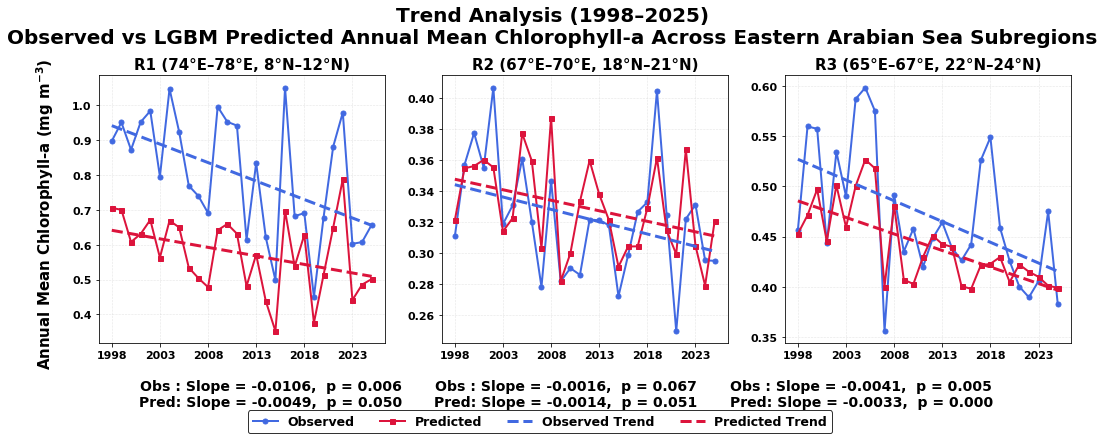

[1998 1999 2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011
 2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025]
[0.45681342 0.5597722  0.5574326  0.44331607 0.5344499  0.49007323
 0.5871156  0.5984002  0.57525104 0.3558587  0.49121264 0.4351865
 0.4579753  0.41990066 0.44832203 0.46420684 0.43881693 0.4264515
 0.44215178 0.5260349  0.5489193  0.45887622 0.42564857 0.40026173
 0.38958094 0.40568724 0.4751279  0.38261738]
[0.45288467 0.47131804 0.497106   0.4455     0.50115293 0.45938906
 0.50046843 0.52671903 0.51804334 0.40031385 0.4808464  0.40714216
 0.4028107  0.4298137  0.45100102 0.44258675 0.43975762 0.40065733
 0.3979989  0.42148378 0.4229349  0.42965588 0.40477166 0.42224202
 0.4150039  0.40996906 0.40115845 0.39903173]
-0.004133118939451918 0.005215711953352829
-0.003292964499180735 5.50345454392728e-05


In [5]:

# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# Eastern Arabian Sea Subregions (1998–2025)
# ==========================================================


# ==========================================================
# Subregions
# ==========================================================

regions = {
    "R1 (74°E–78°E, 8°N–12°N)": [74, 78, 8, 12],
    "R2 (67°E–70°E, 18°N–21°N)": [67, 70, 18, 21],
    "R3 (65°E–67°E, 22°N–24°N)": [65, 67, 22, 24],
}

# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# ==========================================================
# Figure
# ==========================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15,6),
    #sharey=True
)

# ==========================================================
# Loop over regions
# ==========================================================

for ax, (region_name, box) in zip(axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # Annual Mean
    # ------------------------------------------------------

    # Annual means
    obs_year = obs.groupby("time.year").mean()
    pred_year = pred.groupby("time.year").mean()

    # Convert to pandas Series
    obs_series = obs_year.to_series()
    pred_series = pred_year.to_series()

    # Keep only common years
    annual = obs_series.to_frame("Observed").join(
        pred_series.to_frame("Predicted"),
        how="inner"
    )

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["Predicted"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    # Store statistics for later display
    if "stats_list" not in locals():
        stats_list = []

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue
        )
    )

    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="royalblue",
        marker="o",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="Observed"
    )

    ax.plot(
        years,
        pred_values,
        color="crimson",
        marker="s",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="Predicted"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="royalblue",
        linewidth=3,
        label="Observed Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="crimson",
        linewidth=3,
        label="Predicted Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=15,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.6,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(1998,2026,5)
    )

    ax.tick_params(
        labelsize=11
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.02,
    0.5,
    "Annual Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=15,
    fontweight="bold"
)

# ==========================================================
# Common Legend
# ==========================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5,-0.01),
    ncol=4,
    fontsize=12.5,
    frameon=True,
    edgecolor="black"
)
# ==========================================================
# Statistics below each subplot
# ==========================================================

for ax, stat in zip(axes, stats_list):

    obs_slope, obs_p, pred_slope, pred_p = stat

    pos = ax.get_position()

    fig.text(
        pos.x0 + pos.width/2,
        pos.y0 - 0.007,
        f"Obs : Slope = {obs_slope:.4f},  p = {obs_p:.3f}\n"
        f"Pred: Slope = {pred_slope:.4f},  p = {pred_p:.3f}",
        ha="center",
        va="top",
        fontsize=14,
        fontweight="bold"
    )

# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Trend Analysis (1998–2025)\nObserved vs LGBM Predicted Annual Mean Chlorophyll-a Across Eastern Arabian Sea Subregions",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.82,
    bottom=0.20,
    left=0.08,
    right=0.98,
    wspace=0.20
)

plt.show()


print(years)

print(obs_values)

print(pred_values)

print(obs_fit.slope, obs_fit.pvalue)

print(pred_fit.slope, pred_fit.pvalue)

/usr/lib/python3/dist-packages/xarray/core/nanops.py:142: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis=axis, dtype=dtype)


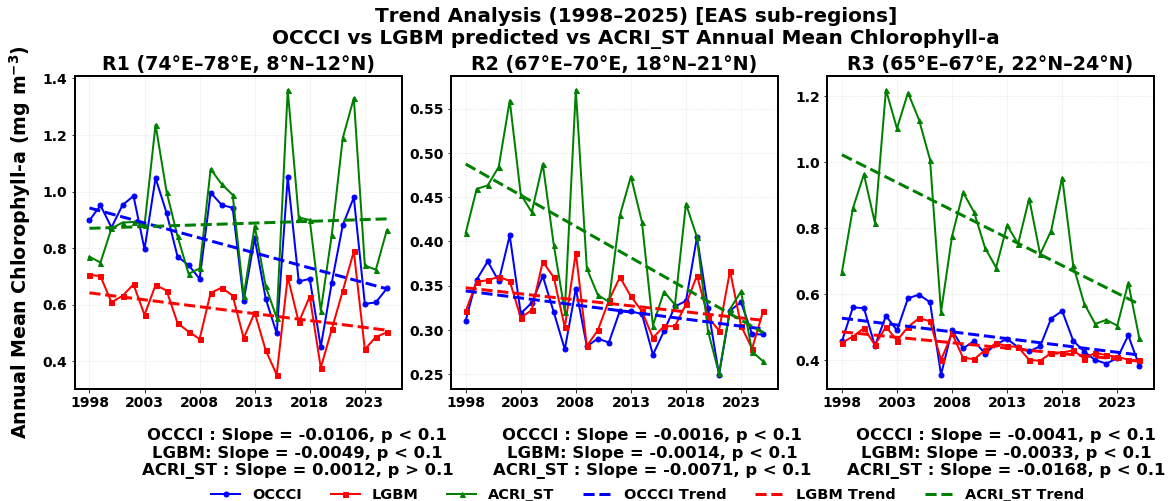

In [60]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# Eastern Arabian Sea Subregions (1998–2025)
# ==========================================================


# ==========================================================
# Subregions
# ==========================================================

regions = {
    "R1 (74°E–78°E, 8°N–12°N)": [74, 78, 8, 12],
    "R2 (67°E–70°E, 18°N–21°N)": [67, 70, 18, 21],
    "R3 (65°E–67°E, 22°N–24°N)": [65, 67, 22, 24],
}

# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# ==========================================================
# Figure
# ==========================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18,6.8),
    #sharey=True
)

# ==========================================================
# Loop over regions
# ==========================================================

stats_list = []
for ax, (region_name, box) in zip(axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # Annual Mean
    # ------------------------------------------------------

    # Annual means
    obs_year = obs.groupby("time.year").mean()
    pred_year = pred.groupby("time.year").mean()
    gap_year = gap.groupby("time.year").mean()

    # Convert to pandas Series
    obs_series = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series = gap_year.to_series()

    # Keep only common years
    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=3,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=3,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=3,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=19,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.6,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(1998,2026,5)
    )

    ax.tick_params(
        labelsize=14,
        
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(2)    

# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.015,
    0.5,
    "Annual Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=19,
    fontweight="bold"
)

# ==========================================================
# Common Legend
# ==========================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5,-0.0290),
    ncol=6,
    fontsize=14.5,
    frameon=False,
    #edgecolor="black"
)
# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"

# ==========================================================
# Statistics below each subplot
# ==========================================================

for ax, stat in zip(axes, stats_list):

    obs_slope, obs_p, pred_slope, pred_p, gap_slope, gap_p = stat

    obs_p_txt  = format_p(obs_p)
    pred_p_txt = format_p(pred_p)
    gap_p_txt  = format_p(gap_p)

    pos = ax.get_position()

    fig.text(
        pos.x0 + pos.width/2,
        pos.y0 - 0.005,
        f"OCCCI : Slope = {obs_slope:.4f}, {obs_p_txt}\n"
        f"LGBM: Slope = {pred_slope:.4f}, {pred_p_txt}\n"
        f"ACRI_ST : Slope = {gap_slope:.4f}, {gap_p_txt}",
        ha="center",
        va="top",
        fontsize=16.45,
        fontweight="bold"
    )

# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Trend Analysis (1998–2025) [EAS sub-regions]\nOCCCI vs LGBM predicted vs ACRI_ST Annual Mean Chlorophyll-a\n",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.84,
    bottom=0.20,
    left=0.067,
    right=0.90,
    wspace=0.150
)




plt.show()




/usr/lib/python3/dist-packages/xarray/core/nanops.py:142: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis=axis, dtype=dtype)
/usr/lib/python3/dist-packages/xarray/core/nanops.py:142: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis=axis, dtype=dtype)


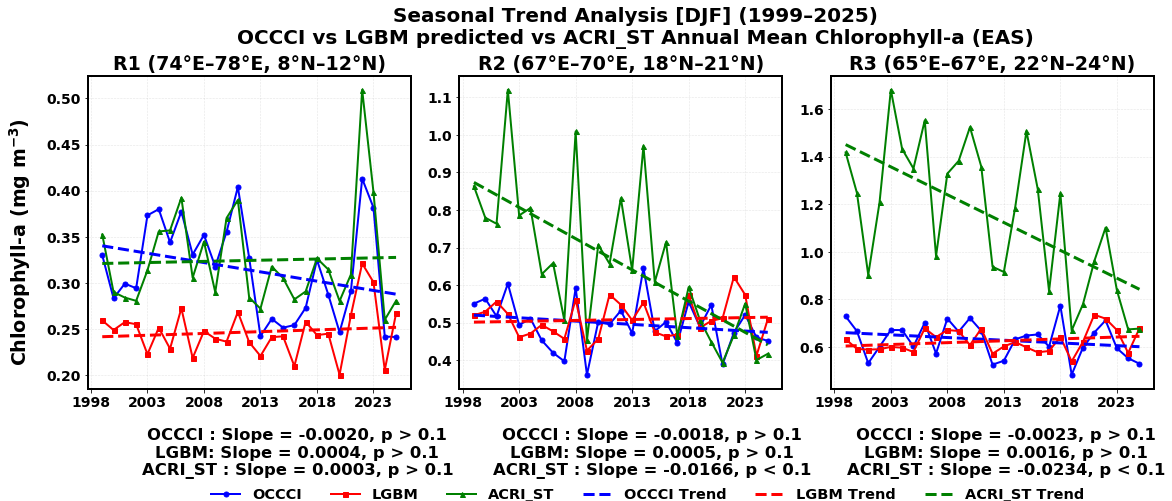

In [59]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# Eastern Arabian Sea Subregions (1998–2025)
# ==========================================================


# ==========================================================
# Subregions
# ==========================================================

regions = {
    "R1 (74°E–78°E, 8°N–12°N)": [74, 78, 8, 12],
    "R2 (67°E–70°E, 18°N–21°N)": [67, 70, 18, 21],
    "R3 (65°E–67°E, 22°N–24°N)": [65, 67, 22, 24],
}

# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# ==========================================================
# Figure
# ==========================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18,6.8),
    #sharey=True
)

# ==========================================================
# Loop over regions
# ==========================================================


stats_list = []
for ax, (region_name, box) in zip(axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # DJF Seasonal Mean
    # (Dec of previous year + Jan + Feb)
    # ------------------------------------------------------

    def seasonal_mean_djf(da):

        season_year = xr.where(
            da.time.dt.month == 12,
            da.time.dt.year + 1,
            da.time.dt.year
        )

        djf = da.where(
            da.time.dt.month.isin([12, 1, 2]),
            drop=True
        )

        djf = djf.assign_coords(
            season_year=("time", season_year.sel(time=djf.time).values)
        )

        return djf.groupby("season_year").mean()

    obs_year  = seasonal_mean_djf(obs)
    pred_year = seasonal_mean_djf(pred)
    gap_year  = seasonal_mean_djf(gap)

    obs_series  = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series  = gap_year.to_series()

    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    annual = annual.loc[1999:2025]

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    # Store statistics for later display
    #if "stats_list" not in locals():
        #stats_list = []

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=3,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=3,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=3,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=19,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.6,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(1998,2026,5)
    )

    ax.tick_params(
        labelsize=14,
        
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(2)    

# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.015,
    0.5,
    "Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=19,
    fontweight="bold"
)

# ==========================================================
# Common Legend
# ==========================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5,-0.0290),
    ncol=6,
    fontsize=14.5,
    frameon=False,
    #edgecolor="black"
)
# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"

# ==========================================================
# Statistics below each subplot
# ==========================================================

for ax, stat in zip(axes, stats_list):

    obs_slope, obs_p, pred_slope, pred_p, gap_slope, gap_p = stat

    obs_p_txt  = format_p(obs_p)
    pred_p_txt = format_p(pred_p)
    gap_p_txt  = format_p(gap_p)

    pos = ax.get_position()

    fig.text(
        pos.x0 + pos.width/2,
        pos.y0 - 0.005,
        f"OCCCI : Slope = {obs_slope:.4f}, {obs_p_txt}\n"
        f"LGBM: Slope = {pred_slope:.4f}, {pred_p_txt}\n"
        f"ACRI_ST : Slope = {gap_slope:.4f}, {gap_p_txt}",
        ha="center",
        va="top",
        fontsize=16.45,
        fontweight="bold"
    )


# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Seasonal Trend Analysis [DJF] (1999–2025)\nOCCCI vs LGBM predicted vs ACRI_ST Annual Mean Chlorophyll-a (EAS)",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.84,
    bottom=0.20,
    left=0.077,
    right=0.90,
    wspace=0.150
)

plt.show()

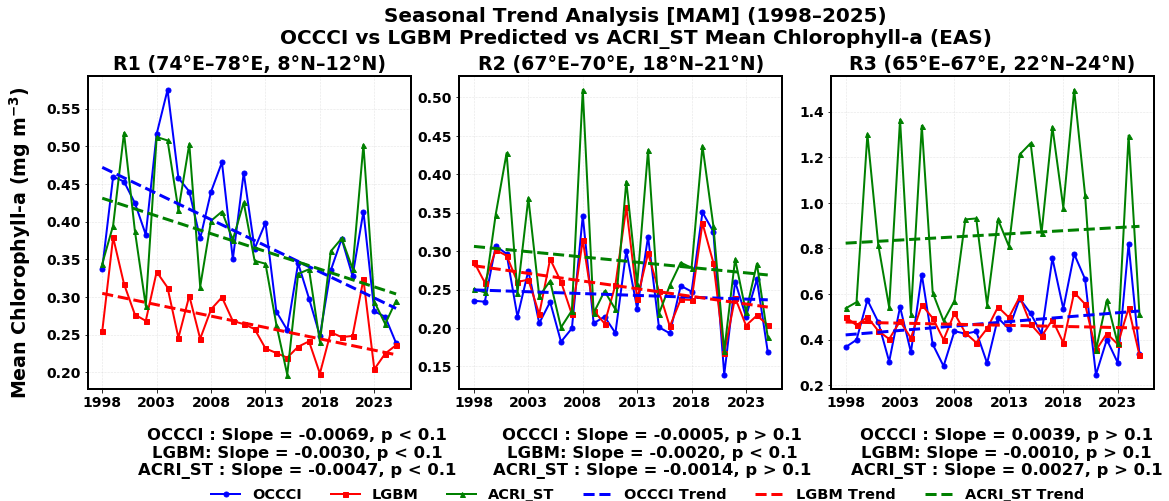

In [58]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# Eastern Arabian Sea Subregions (1998–2025)
# ==========================================================


# ==========================================================
# Subregions
# ==========================================================

regions = {
    "R1 (74°E–78°E, 8°N–12°N)": [74, 78, 8, 12],
    "R2 (67°E–70°E, 18°N–21°N)": [67, 70, 18, 21],
    "R3 (65°E–67°E, 22°N–24°N)": [65, 67, 22, 24],
}

# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# ==========================================================
# Figure
# ==========================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18,6.8),
    #sharey=True
)

# ==========================================================
# Loop over regions
# ==========================================================

stats_list = []
for ax, (region_name, box) in zip(axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # MAM Seasonal Mean
    # (March + April + May)
    # ------------------------------------------------------

    def seasonal_mean_mam(da):

        mam = da.where(
            da.time.dt.month.isin([3, 4, 5]),
            drop=True
        )

        return mam.groupby("time.year").mean()

    obs_year  = seasonal_mean_mam(obs)
    
    pred_year = seasonal_mean_mam(pred)
    gap_year  = seasonal_mean_mam(gap)

    obs_series  = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series  = gap_year.to_series()

    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    annual = annual.loc[1998:2025]

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    
    
    # Store statistics for later display
    #if "stats_list" not in locals():
        #stats_list = []

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=3,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=3,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=3,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=19,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.6,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(1998,2026,5)
    )

    ax.tick_params(
        labelsize=14,
        
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(2)    

# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.015,
    0.5,
    "Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=19,
    fontweight="bold"
)

# ==========================================================
# Common Legend
# ==========================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5,-0.0290),
    ncol=6,
    fontsize=14.5,
    frameon=False,
    #edgecolor="black"
)
# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"

# ==========================================================
# Statistics below each subplot
# ==========================================================

for ax, stat in zip(axes, stats_list):

    obs_slope, obs_p, pred_slope, pred_p, gap_slope, gap_p = stat

    obs_p_txt  = format_p(obs_p)
    pred_p_txt = format_p(pred_p)
    gap_p_txt  = format_p(gap_p)

    pos = ax.get_position()

    fig.text(
        pos.x0 + pos.width/2,
        pos.y0 - 0.005,
        f"OCCCI : Slope = {obs_slope:.4f}, {obs_p_txt}\n"
        f"LGBM: Slope = {pred_slope:.4f}, {pred_p_txt}\n"
        f"ACRI_ST : Slope = {gap_slope:.4f}, {gap_p_txt}",
        ha="center",
        va="top",
        fontsize=16.45,
        fontweight="bold"
    )


# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Seasonal Trend Analysis [MAM] (1998–2025)\nOCCCI vs LGBM Predicted vs ACRI_ST Mean Chlorophyll-a (EAS)",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.84,
    bottom=0.20,
    left=0.077,
    right=0.90,
    wspace=0.150
)

plt.show()

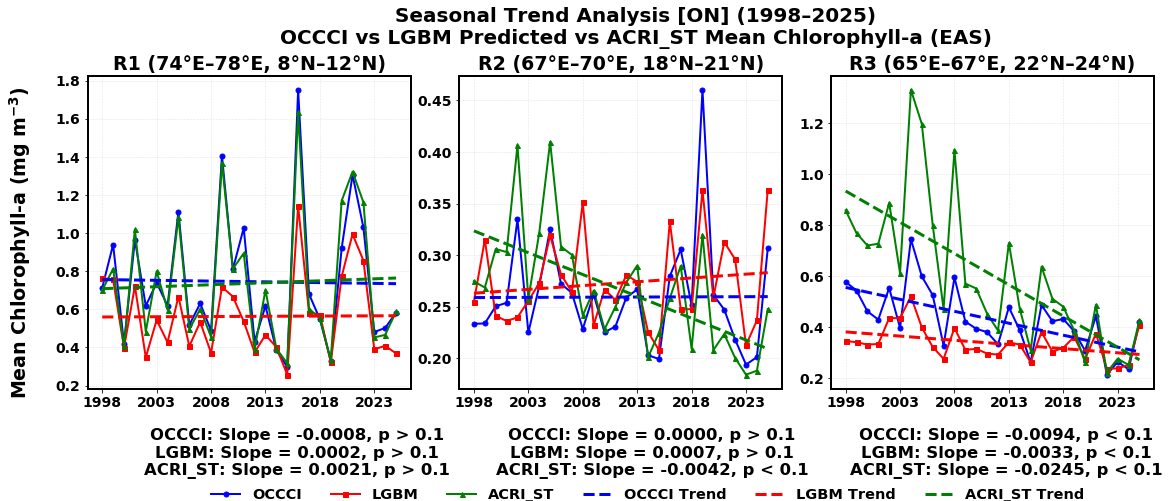

In [57]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# Eastern Arabian Sea Subregions (1998–2025)
# ==========================================================


# ==========================================================
# Subregions
# ==========================================================

regions = {
    "R1 (74°E–78°E, 8°N–12°N)": [74, 78, 8, 12],
    "R2 (67°E–70°E, 18°N–21°N)": [67, 70, 18, 21],
    "R3 (65°E–67°E, 22°N–24°N)": [65, 67, 22, 24],
}

# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# ==========================================================
# Figure
# ==========================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18,6.8),
    #sharey=True
)

# ==========================================================
# Loop over regions
# ==========================================================

stats_list = []
for ax, (region_name, box) in zip(axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # ON Seasonal Mean
    # (October + November)
    # ------------------------------------------------------

    def seasonal_mean_on(da):

        on = da.where(
            da.time.dt.month.isin([10, 11]),
            drop=True
        )

        return on.groupby("time.year").mean()

    obs_year  = seasonal_mean_on(obs)
    pred_year = seasonal_mean_on(pred)
    gap_year  = seasonal_mean_on(gap)

    obs_series  = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series  = gap_year.to_series()

    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    annual = annual.loc[1998:2025]

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    # Store statistics for later display
    #if "stats_list" not in locals():
        #stats_list = []

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=3,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=3,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=3,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=19,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.6,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(1998,2026,5)
    )

    ax.tick_params(
        labelsize=14,
        
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(2)    

# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.015,
    0.5,
    "Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=19,
    fontweight="bold"
)

# ==========================================================
# Common Legend
# ==========================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5,-0.0290),
    ncol=6,
    fontsize=14.5,
    frameon=False,
    #edgecolor="black"
)

# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"

# ==========================================================
# Statistics below each subplot
# ==========================================================

for ax, stat in zip(axes, stats_list):

    obs_slope, obs_p, pred_slope, pred_p, gap_slope, gap_p = stat

    obs_p_txt  = format_p(obs_p)
    pred_p_txt = format_p(pred_p)
    gap_p_txt  = format_p(gap_p)

    pos = ax.get_position()

    fig.text(
        pos.x0 + pos.width/2,
        pos.y0 - 0.005,
        f"OCCCI: Slope = {obs_slope:.4f}, {obs_p_txt}\n"
        f"LGBM: Slope = {pred_slope:.4f}, {pred_p_txt}\n"
        f"ACRI_ST: Slope = {gap_slope:.4f}, {gap_p_txt}",
        ha="center",
        va="top",
        fontsize=16.45,
        fontweight="bold"
    )

# ===========================================================
# Figure Title
# ===========================================================

plt.suptitle(
    "Seasonal Trend Analysis [ON] (1998–2025)\nOCCCI vs LGBM Predicted vs ACRI_ST Mean Chlorophyll-a (EAS)",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.84,
    bottom=0.20,
    left=0.077,
    right=0.90,
    wspace=0.150
)

plt.show()

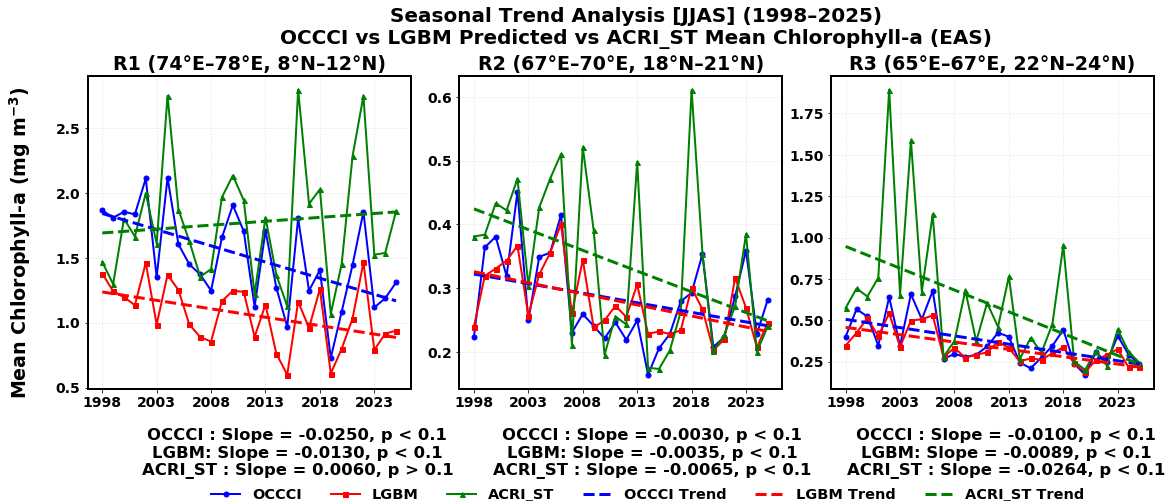

In [55]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# Eastern Arabian Sea Subregions (1998–2025)
# ==========================================================


# ==========================================================
# Subregions
# ==========================================================

regions = {
    "R1 (74°E–78°E, 8°N–12°N)": [74, 78, 8, 12],
    "R2 (67°E–70°E, 18°N–21°N)": [67, 70, 18, 21],
    "R3 (65°E–67°E, 22°N–24°N)": [65, 67, 22, 24],
}

# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# ==========================================================
# Figure
# ==========================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18,6.8),
    #sharey=True
)

# ==========================================================
# Loop over regions
# ==========================================================

stats_list = []
for ax, (region_name, box) in zip(axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # JJAS Seasonal Mean
    # (June + July + August + September)
    # ------------------------------------------------------

    def seasonal_mean_jjas(da):

        jjas = da.where(
            da.time.dt.month.isin([6, 7, 8, 9]),
            drop=True
        )

        return jjas.groupby("time.year").mean()

    obs_year  = seasonal_mean_jjas(obs)
    pred_year = seasonal_mean_jjas(pred)
    gap_year  = seasonal_mean_jjas(gap)

    obs_series  = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series  = gap_year.to_series()

    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    annual = annual.loc[1998:2025]

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    # Store statistics for later display
    #if "stats_list" not in locals():
        #stats_list = []

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=2,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=3,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=3,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=3,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=19,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.6,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(1998,2026,5)
    )

    ax.tick_params(
        labelsize=14,
        
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(2)    

# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.015,
    0.5,
    "Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=19,
    fontweight="bold"
)

# ==========================================================
# Common Legend
# ==========================================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5,-0.0290),
    ncol=6,
    fontsize=14.5,
    frameon=False,
    #edgecolor="black"
)


# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"

# ==========================================================
# Statistics below each subplot
# ==========================================================

for ax, stat in zip(axes, stats_list):

    obs_slope, obs_p, pred_slope, pred_p, gap_slope, gap_p = stat

    obs_p_txt  = format_p(obs_p)
    pred_p_txt = format_p(pred_p)
    gap_p_txt  = format_p(gap_p)

    pos = ax.get_position()

    fig.text(
        pos.x0 + pos.width/2,
        pos.y0 - 0.005,
        f"OCCCI : Slope = {obs_slope:.4f}, {obs_p_txt}\n"
        f"LGBM: Slope = {pred_slope:.4f}, {pred_p_txt}\n"
        f"ACRI_ST : Slope = {gap_slope:.4f}, {gap_p_txt}",
        ha="center",
        va="top",
        fontsize=16.45,
        fontweight="bold"
    )

# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Seasonal Trend Analysis [JJAS] (1998–2025)\nOCCCI vs LGBM Predicted vs ACRI_ST Mean Chlorophyll-a (EAS)",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.84,
    bottom=0.20,
    left=0.077,
    right=0.90,
    wspace=0.150
)

plt.show()